# 01 Datuen karga eta EDA

Barakaldoko estazioaren datuak kargatu, haien kalitatea begiratu eta lehen ondorioak atera nahi ditugu. EDA 2023-2025eko datuekin egiten dugu, ereduak urte horiekin entrenatuko baititugu; 2026a proba da eta amaieran bakarrik begiratzen dugu.

Datuak Open Data Euskadiko airearen kalitatearen saretik datoz: orduko datuak eta kalitate-indizea (ICA).

In [1]:
# Liburutegiak
import sys
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Gure funtzioak src karpetatik inportatu ahal izateko
sys.path.append("../src")
from karga import datuak_kargatu, estazioa_kargatu, ICA_ORDENA

# Grafikoen estiloa
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 4)

## 1. Datuen karga

CSVek arazo txiki batzuk dituzte, src/karga.py fitxategiko datuak_kargatu funtzioak konpontzen dituenak:: bereizlea eta koma hamartarra, 24:00 ordua (hurrengo eguneko 00:00 bihurtzen dugu), errenkadak alderantzizko ordenan, 2023ko zutabeen ordena desberdina eta ICA etiketak urtearen arabera idatzita (Oso ona, Ona, Erregularra, Txarra bihurtzen ditugu).

Neurketak orduko fitxategitik hartzen ditugu, eta indize-fitxategitik ICA kategoriak bakarrik.

In [2]:
# Hiru urteak kargatu eta elkartu
df = datuak_kargatu("../data/jatorrizkoak", [2023, 2024, 2025])

print("Errenkadak eta zutabeak:", df.shape)
print("Noiztik", df.index.min(), "noiz arte", df.index.max())
df.head()

Urtea 2023 -> 8760 errenkada
Urtea 2024 -> 8784 errenkada


Urtea 2025 -> 8760 errenkada
Errenkadak eta zutabeak: (26304, 18)
Noiztik 2023-01-01 01:00:00 noiz arte 2026-01-01 00:00:00


,CO,CO_8h,NO,NOX,NO2,PM10,PM25,SO2,haize_norabidea,hezetasuna,tenperatura,haize_abiadura,ICA_NO2,ICA_PM10,ICA_PM25,ICA_SO2,ICA_estazioa,urtea
data,,,,,,,,,,,,,,,,,,
2023-01-01 01:00:00,0.18,0.15,2.0,17.0,15.0,113.0,90.0,8.0,191.0,31.0,19.9,0.48,Oso ona,Ona,Ona,Oso ona,Ona,2023
2023-01-01 02:00:00,0.14,0.15,1.0,10.0,9.0,315.0,288.0,6.0,65.0,33.0,19.8,0.72,Oso ona,Erregularra,Txarra,Oso ona,Txarra,2023
2023-01-01 03:00:00,0.11,0.14,1.0,4.0,3.0,47.0,46.0,6.0,203.0,34.0,20.2,1.17,Oso ona,Erregularra,Txarra,Oso ona,Txarra,2023
2023-01-01 04:00:00,0.31,0.16,1.0,3.0,2.0,33.0,34.0,6.0,220.0,35.0,20.2,0.67,Oso ona,Erregularra,Txarra,Oso ona,Txarra,2023
2023-01-01 05:00:00,0.27,0.17,0.0,5.0,5.0,32.0,33.0,6.0,52.0,38.0,19.3,1.00,Oso ona,Erregularra,Txarra,Oso ona,Txarra,2023


In [ ]:
##Zutabe bakoitzaren datu-mota
df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 26304 entries, 2023-01-01 01:00:00 to 2026-01-01 00:00:00
Data columns (total 18 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   CO               26026 non-null  float64
 1   CO_8h            26080 non-null  float64
 2   NO               26031 non-null  float64
 3   NOX              26006 non-null  float64
 4   NO2              26039 non-null  float64
 5   PM10             21291 non-null  float64
 6   PM25             25459 non-null  float64
 7   SO2              25658 non-null  float64
 8   haize_norabidea  24744 non-null  float64
 9   hezetasuna       24744 non-null  float64
 10  tenperatura      24738 non-null  float64
 11  haize_abiadura   24744 non-null  float64
 12  ICA_NO2          26039 non-null  str    
 13  ICA_PM10         20164 non-null  str    
 14  ICA_PM25         23973 non-null  str    
 15  ICA_SO2          25658 non-null  str    
 16  ICA_estazioa     26216 non-null  s

Aldagaiak: CO eta CO_8h (mg/m³), NO, NOX eta NO2, PM10 eta PM25, SO2 (µg/m³), haizearen norabidea (graduak) eta abiadura (m/s), tenperatura (ºC), hezetasuna (%) eta ICA kategoriak (testua).

## 2. Datuen kalitatea

In [4]:
# Ordurik falta ez dela eta errepikatutako ordurik ez dagoela egiaztatu
espero_orduak = pd.date_range(df.index.min(), df.index.max(), freq="h")
print("Espero diren orduak:", len(espero_orduak))
print("Datu-multzoko orduak:", len(df))
print("Falta diren orduak:", len(espero_orduak.difference(df.index)))
print("Bikoiztutako datak:", df.index.duplicated().sum())

Espero diren orduak: 26304
Datu-multzoko orduak: 26304
Falta diren orduak: 0
Bikoiztutako datak: 0


In [5]:
# Balio nuluen ehunekoa zutabeka
nuluak = df.isna().mean() * 100
nuluak.round(2).sort_values(ascending=False)

ICA_PM10           23.34
PM10               19.06
ICA_PM25            8.86
tenperatura         5.95
haize_abiadura      5.93
hezetasuna          5.93
haize_norabidea     5.93
PM25                3.21
ICA_SO2             2.46
SO2                 2.46
NOX                 1.13
CO                  1.06
NO                  1.04
NO2                 1.01
ICA_NO2             1.01
CO_8h               0.85
ICA_estazioa        0.33
urtea               0.00
dtype: float64

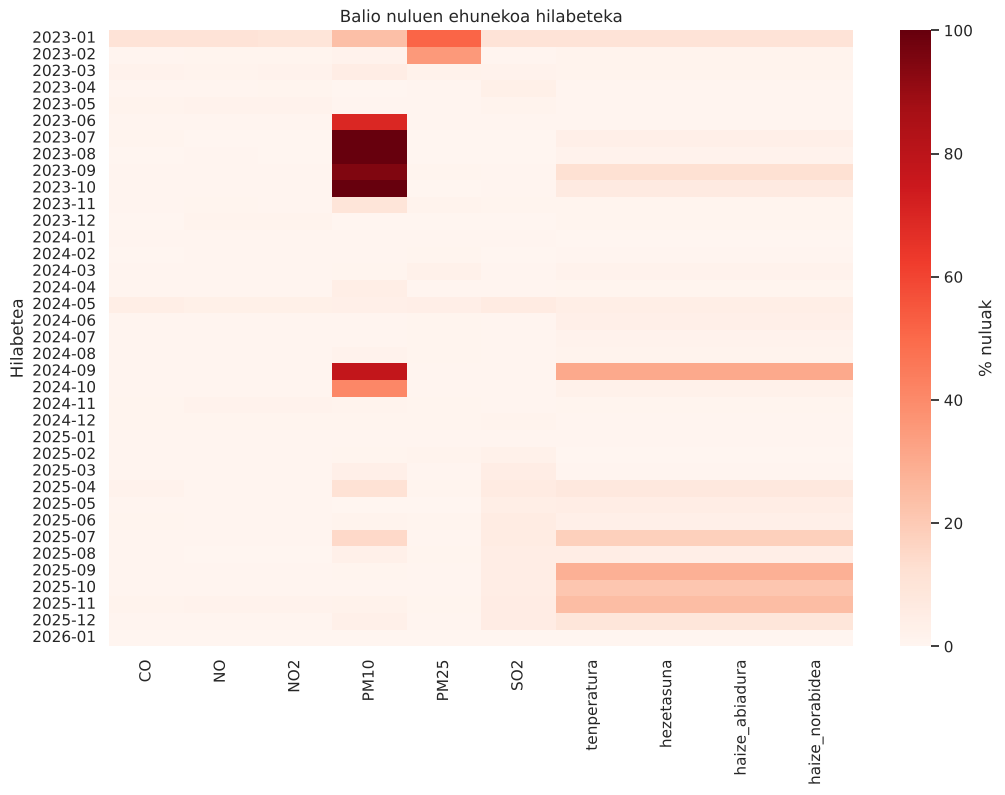

In [ ]:
# Nuluen mapa hilabeteka: horrela ikusten dugu non dauden hutsuneak
neurketa_zutabeak = ["CO", "NO", "NO2", "PM10", "PM25", "SO2", "tenperatura", "hezetasuna", "haize_abiadura", "haize_norabidea"]
nuluak_hilabeteka = df[neurketa_zutabeak].isna().groupby(df.index.to_period("M")).mean() * 100

plt.figure(figsize=(12, 8))
sns.heatmap(nuluak_hilabeteka, cmap="Reds", vmin=0, vmax=100, cbar_kws={"label": "% nuluak"})
plt.title("Balio nuluen ehunekoa hilabeteka")
plt.ylabel("Hilabetea")
plt.show()

In [7]:
# Zenbat nulu dago aldagai bakoitzean urte bakoitzean (%)
(df[neurketa_zutabeak].isna().groupby(df.index.year).mean() * 100).round(1)

,CO,NO,NO2,PM10,PM25,SO2,tenperatura,hezetasuna,haize_abiadura,haize_norabidea
data,,,,,,,,,,
2023,1.5,1.6,1.6,42.4,7.6,1.7,3.5,3.5,3.5,3.5
2024,0.9,0.9,0.9,11.1,1.3,1.1,4.1,4.1,4.1,4.1
2025,0.7,0.6,0.6,3.6,0.7,4.6,10.3,10.3,10.3,10.3
2026,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


#### Ondorioak

- 26.304 ordu daude, bat ere falta gabe eta errepikatu gabe.
- Gasek (NO2, NO, CO, SO2) nulu gutxi dituzte, % 1-2,5.
- PM10 da okerrena: % 19 falta da, ia dena 2023ko udan eta 2024ko udazkenean.
- Meteorologia ordu berberetan falta da (ekipo bera da), % 6 inguru.
- Nuluak Pipeline-aren barruan beteko ditugu (02 koadernoan erabakitzen dugu nola).

## 3. Estatistika deskribatzailea eta lege-mugak

In [8]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
CO,26026.0,0.22,0.08,0.00,0.18,0.21,0.25,2.37
CO_8h,26080.0,0.22,0.06,0.05,0.18,0.21,0.25,0.88
NO,26031.0,4.48,8.69,0.00,1.00,2.00,4.00,170.00
NOX,26006.0,24.88,22.99,0.00,10.00,17.00,32.00,321.00
NO2,26039.0,18.45,12.94,0.00,9.00,15.00,26.00,85.00
PM10,21291.0,20.80,13.84,2.00,12.00,18.00,26.00,364.00
PM25,25459.0,8.68,7.60,0.00,4.00,7.00,12.00,288.00
SO2,25658.0,5.91,4.16,0.00,3.00,5.00,7.00,67.00
haize_norabidea,24744.0,188.96,102.03,1.00,99.00,166.00,293.00,360.00
hezetasuna,24744.0,69.29,14.40,17.00,59.00,71.00,81.00,100.00


In [9]:
# Kutsatzaile bakoitzaren urteko batez bestekoa
df.groupby("urtea")[["NO2", "PM10", "PM25", "SO2", "CO"]].mean().round(1)

,NO2,PM10,PM25,SO2,CO
urtea,,,,,
2023,16.9,22.5,9.3,7.3,0.2
2024,19.7,19.9,8.2,5.3,0.2
2025,18.8,20.6,8.6,5.1,0.2


In [ ]:
# Europako  lege-mugekin alderaketa
# NO2: urteko batez bestekoa 40 ug/m3 eta orduko balioa 200 ug/m3
# PM10: eguneko batez bestekoa 50 ug/m3 (urtean gehienez 35 egun) eta urteko batez bestekoa 40 ug/m3
# PM2.5: urteko batez bestekoa 25 ug/m3
print("NO2 > 200 duten orduak:", (df["NO2"] > 200).sum(), "| NO2 maximoa:", df["NO2"].max())

pm10_egunekoa = df["PM10"].resample("D").mean()
gainditutako_egunak = (pm10_egunekoa > 50).groupby(pm10_egunekoa.index.year).sum()
datudun_egunak = pm10_egunekoa.notna().groupby(pm10_egunekoa.index.year).sum()
pd.DataFrame({"PM10 > 50 egunak": gainditutako_egunak, "datudun egunak": datudun_egunak}).loc[[2023, 2024, 2025]]

NO2 > 200 duten orduak: 0 | NO2 maximoa: 85.0


,PM10 > 50 egunak,datudun egunak
data,,
2023,11,217
2024,2,337
2025,5,361


#### Ondorioak

Urteko batez bestekoak lege-mugen azpitik daude (NO2 17-20, PM10 20-23 eta PM2.5 8-9 µg/m³). PM10ak eguneko 50eko muga egun gutxi batzuetan gainditzen du (11 egun 2023an). Hala ere, noizbehinkako gailur oso altuak daude (PM10 364 arte), outlierren atalean ikusiko ditugunak.

## 4. Banaketak

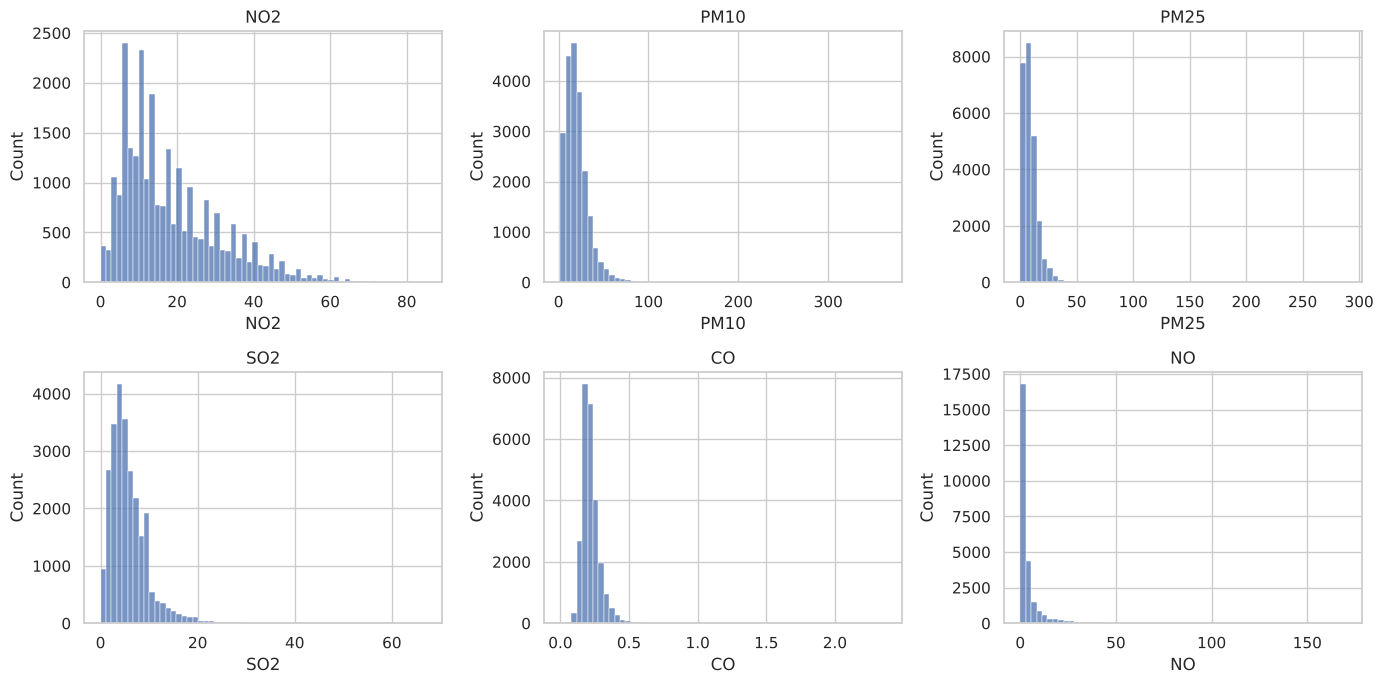

In [11]:
# Kutsatzaile nagusien histogramak
aldagaiak = ["NO2", "PM10", "PM25", "SO2", "CO", "NO"]
fig, ardatzak = plt.subplots(2, 3, figsize=(14, 7))
for ardatza, aldagaia in zip(ardatzak.flatten(), aldagaiak):
    sns.histplot(df[aldagaia].dropna(), bins=60, ax=ardatza)
    ardatza.set_title(aldagaia)
plt.tight_layout()
plt.show()

In [12]:
# Asimetria: 1 baino balio handiagoek eskuinerako isats luzea adierazten dute
df[["NO2", "PM10", "PM25", "SO2", "CO", "NO"]].skew().round(2)

NO2     1.13
PM10    3.53
PM25    4.23
SO2     2.77
CO      5.11
NO      5.15
dtype: float64

#### Ondorioak

Kutsatzaile guztiek eskuinerako isatsa dute: ordu gehienak baxuak dira eta gutxi batzuk oso altuak (episodioak). Hori normala da kutsaduran.

## 5. Denbora-serieak

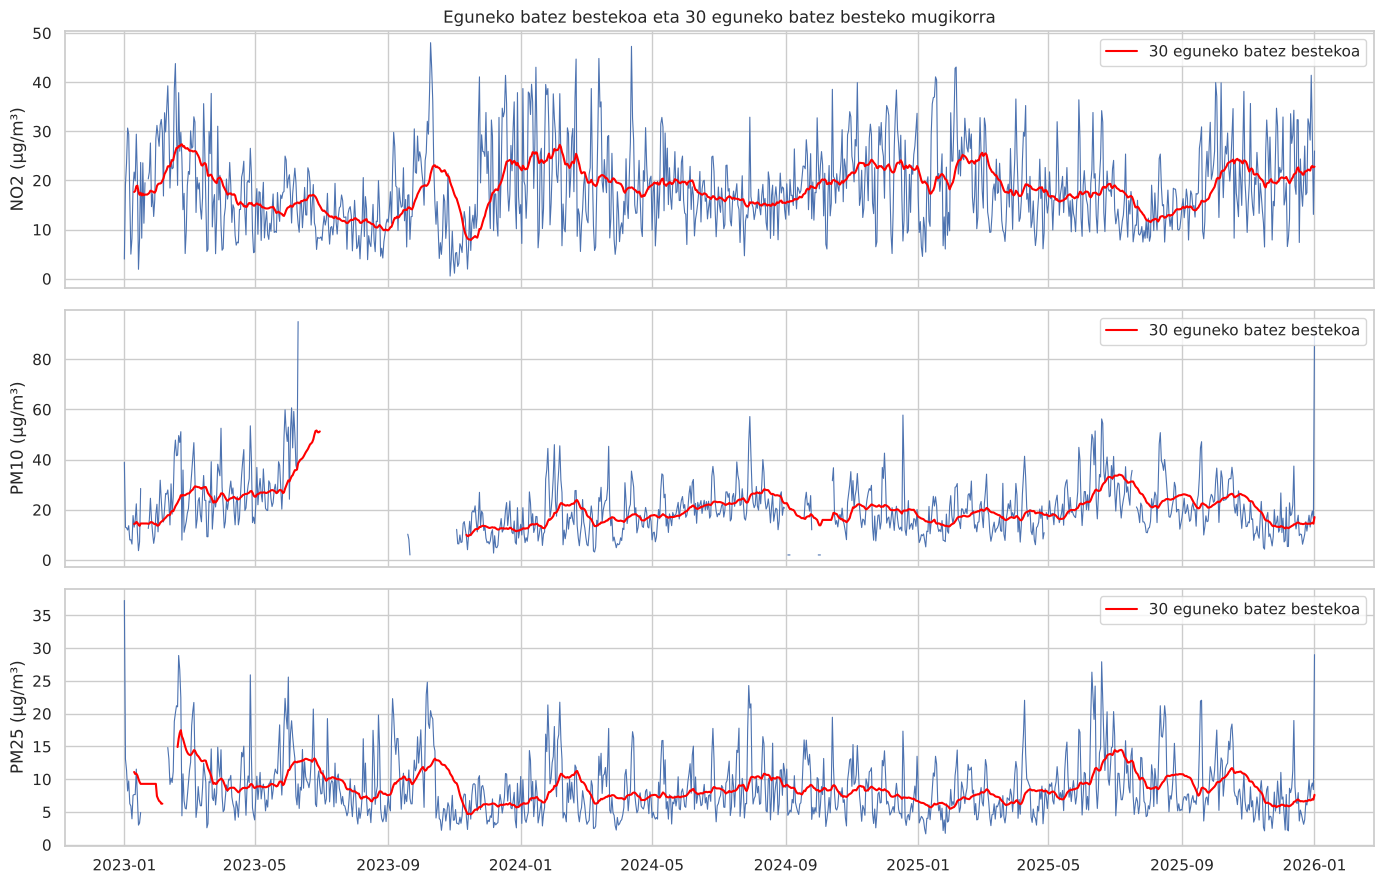

In [13]:
# Kutsatzaile nagusien eguneko batez bestekoak
egunekoa = df[["NO2", "PM10", "PM25"]].resample("D").mean()

fig, ardatzak = plt.subplots(3, 1, figsize=(14, 9), sharex=True)
for ardatza, aldagaia in zip(ardatzak, ["NO2", "PM10", "PM25"]):
    ardatza.plot(egunekoa.index, egunekoa[aldagaia], linewidth=0.8)
    ardatza.plot(egunekoa.index, egunekoa[aldagaia].rolling(30, min_periods=10).mean(), color="red", label="30 eguneko batez bestekoa")
    ardatza.set_ylabel(aldagaia + " (µg/m³)")
    ardatza.legend(loc="upper right")
ardatzak[0].set_title("Eguneko batez bestekoa eta 30 eguneko batez besteko mugikorra")
plt.tight_layout()
plt.show()

#### Ondorioak

NO2a neguan igotzen da eta udan jaisten; PM10ak alderantziz egiten du. Partikulen gailurrak laburrak dira, ordu edo egun gutxikoak. 2023ko PM10 hutsunea grafikoan ere ikusten da.

## 6. Orduko, asteko eta hileko ereduak

In [14]:
# GMT data tokiko ordura pasatzen dugu, puntako orduak ondo interpretatzeko
tokiko_data = df.index.tz_localize("UTC").tz_convert("Europe/Madrid")
df["ordua"] = tokiko_data.hour
df["aste_eguna"] = tokiko_data.dayofweek   # 0 = astelehena
df["hilabetea"] = tokiko_data.month

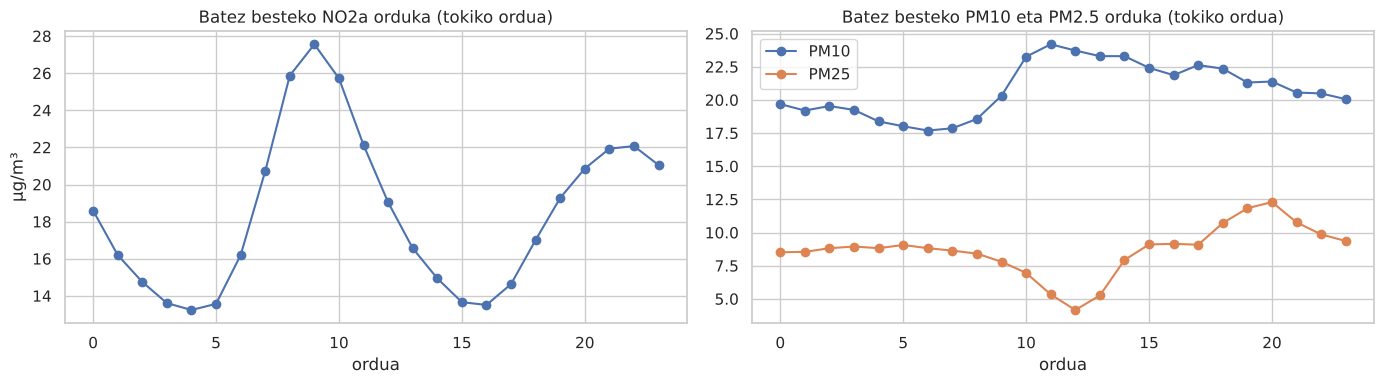

In [ ]:
# Batez besteko profila eguneko orduaren arabera
fig, ardatzak = plt.subplots(1, 2, figsize=(14, 4))
df.groupby("ordua")["NO2"].mean().plot(ax=ardatzak[0], marker="o")
ardatzak[0].set_title("Batez besteko NO2a orduka")
ardatzak[0].set_ylabel("µg/m³")
df.groupby("ordua")[["PM10", "PM25"]].mean().plot(ax=ardatzak[1], marker="o")
ardatzak[1].set_title("Batez besteko PM10 eta PM2.5 orduka")
plt.tight_layout()
plt.show()

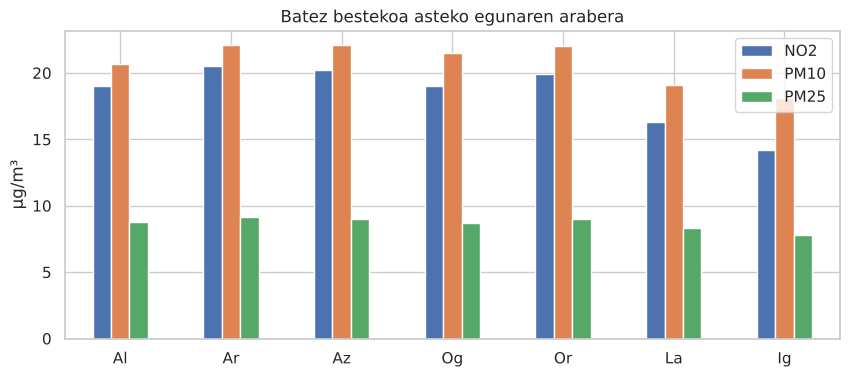

,NO2,PM10,PM25
Al,19.1,20.6,8.8
Ar,20.5,22.1,9.2
Az,20.2,22.1,9.0
Og,19.0,21.5,8.7
Or,19.9,22.1,9.0
La,16.3,19.1,8.3
Ig,14.2,18.1,7.8


In [16]:
# Profila asteko egunaren arabera
egunak = ["Al", "Ar", "Az", "Og", "Or", "La", "Ig"]
egunaren_arabera = df.groupby("aste_eguna")[["NO2", "PM10", "PM25"]].mean()
egunaren_arabera.index = egunak
egunaren_arabera.plot(kind="bar", figsize=(10, 4), rot=0)
plt.title("Batez bestekoa asteko egunaren arabera")
plt.ylabel("µg/m³")
plt.show()
egunaren_arabera.round(1)

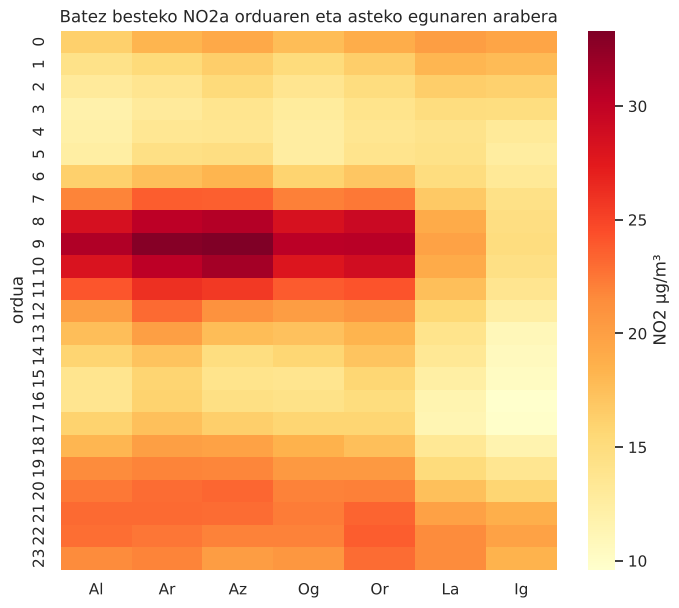

In [ ]:
# NO2aren bero-mapa
taula = df.pivot_table(values="NO2", index="ordua", columns="aste_eguna", aggfunc="mean")
taula.columns = egunak
plt.figure(figsize=(8, 7))
sns.heatmap(taula, cmap="YlOrRd", annot=False, cbar_kws={"label": "NO2 µg/m³"})
plt.title("Batez besteko NO2a orduaren eta asteko egunaren arabera")
plt.show()

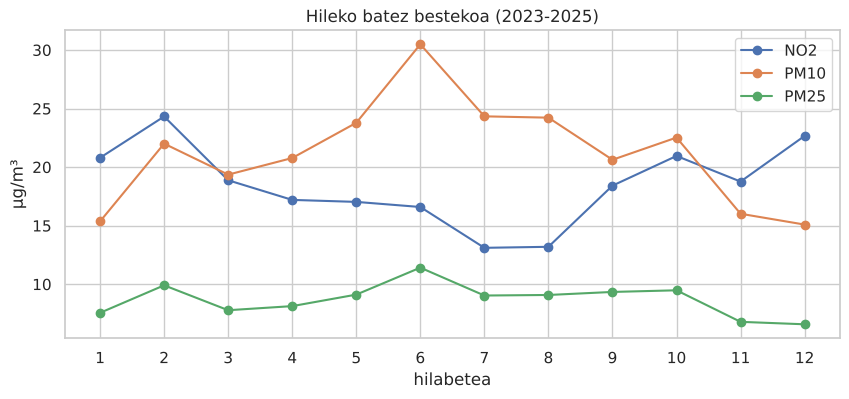

In [18]:
# Profila hilabetearen arabera
hilabetearen_arabera = df.groupby("hilabetea")[["NO2", "PM10", "PM25"]].mean()
hilabetearen_arabera.plot(marker="o", figsize=(10, 4))
plt.title("Hileko batez bestekoa (2023-2025)")
plt.ylabel("µg/m³")
plt.xticks(range(1, 13))
plt.show()

#### Ondorioak

- NO2a trafikoari lotuta dago: goizean (9:00 aldera) eta arratsalde-gauean ditu gailurrak, eta asteburuan asko jaisten da.
- PM10ak egunean zehar egiten du gora eta ia ez du asteburua nabaritzen, beste iturri batzuk dituelako (industria, hautsa).
- Urtaroak: NO2 maximoa neguan, PM10 maximoa ekainean.

## 7. Korrelazioak eta haizearen eragina

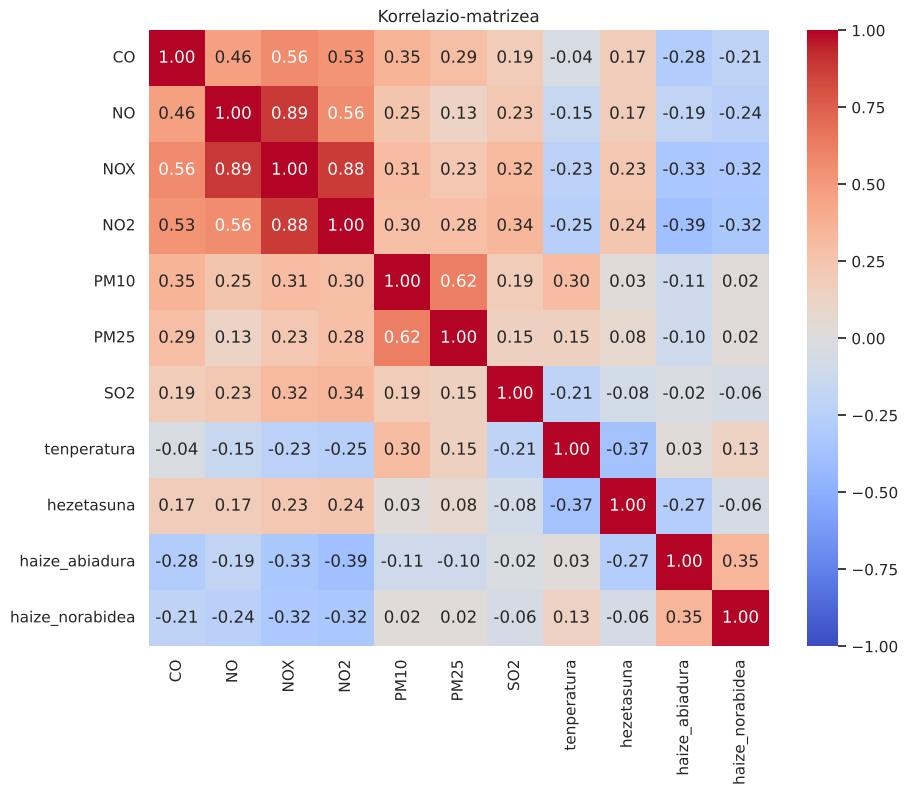

In [19]:
# Korrelazio-matrizea
zutabeak = ["CO", "NO", "NOX", "NO2", "PM10", "PM25", "SO2", "tenperatura", "hezetasuna", "haize_abiadura", "haize_norabidea"]
plt.figure(figsize=(10, 8))
sns.heatmap(df[zutabeak].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Korrelazio-matrizea")
plt.show()

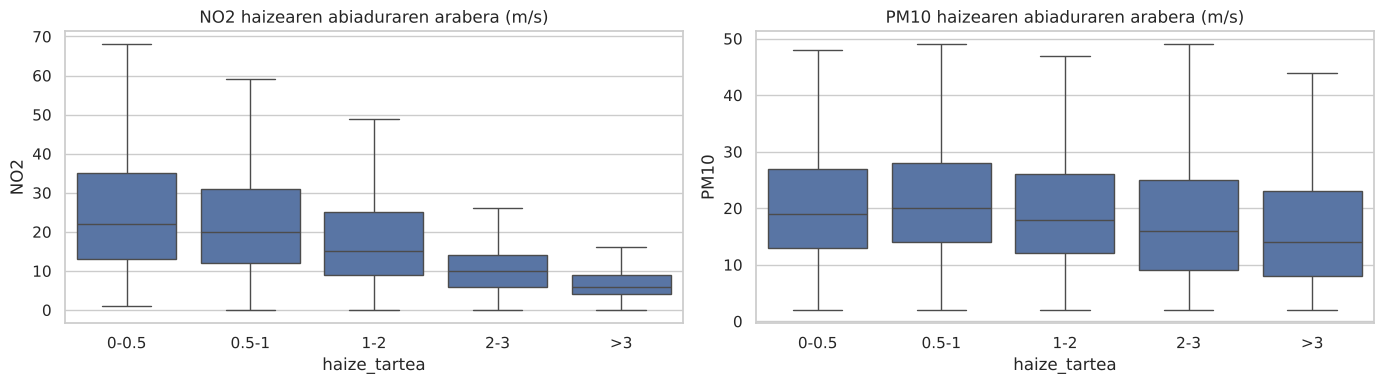

,NO2,PM10
haize_tartea,,
0-0.5,25.1,21.6
0.5-1,22.8,22.3
1-2,18.3,20.9
2-3,11.7,18.2
>3,7.0,17.0


In [20]:
# NO2 eta PM10 haizearen abiaduraren arabera
df["haize_tartea"] = pd.cut(df["haize_abiadura"], bins=[0, 0.5, 1, 2, 3, 10],
                            labels=["0-0.5", "0.5-1", "1-2", "2-3", ">3"])
fig, ardatzak = plt.subplots(1, 2, figsize=(14, 4))
sns.boxplot(data=df, x="haize_tartea", y="NO2", ax=ardatzak[0], showfliers=False)
ardatzak[0].set_title("NO2 haizearen abiaduraren arabera (m/s)")
sns.boxplot(data=df, x="haize_tartea", y="PM10", ax=ardatzak[1], showfliers=False)
ardatzak[1].set_title("PM10 haizearen abiaduraren arabera (m/s)")
plt.tight_layout()
plt.show()

df.groupby("haize_tartea", observed=True)[["NO2", "PM10"]].mean().round(1)

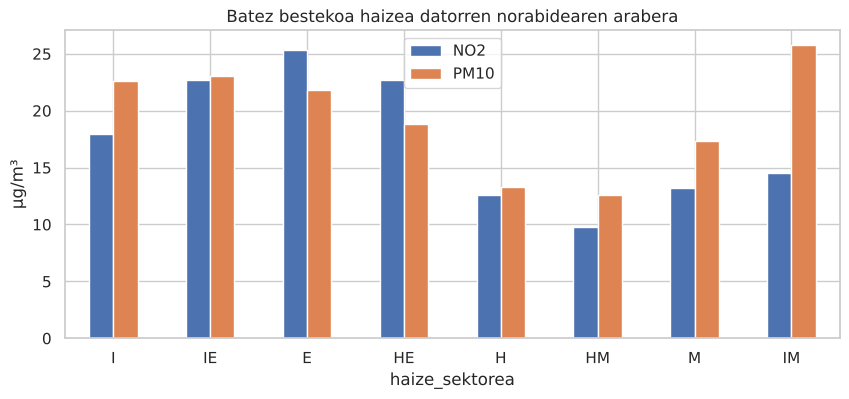

,NO2,PM10,haize_abiadura,orduak
haize_sektorea,,,,
I,17.9,22.7,0.6,1241
IE,22.7,23.1,0.8,2216
E,25.3,21.9,1.2,5330
HE,22.7,18.8,1.2,3866
H,12.6,13.3,1.8,1437
HM,9.8,12.6,1.9,891
M,13.2,17.4,2.0,4103
IM,14.5,25.8,1.7,5660


In [ ]:
# Kutsadura haizea datorren norabidearen arabera
sektoreak = ["I", "IE", "E", "HE", "H", "HM", "M", "IM"]
sektore_zenbakia = ((df["haize_norabidea"] + 22.5) // 45) % 8
df["haize_sektorea"] = sektore_zenbakia.map(lambda x: sektoreak[int(x)] if pd.notna(x) else None)

sektorearen_arabera = df.groupby("haize_sektorea")[["NO2", "PM10", "haize_abiadura"]].mean().loc[sektoreak]
sektorearen_arabera["orduak"] = df["haize_sektorea"].value_counts().loc[sektoreak]

sektorearen_arabera[["NO2", "PM10"]].plot(kind="bar", figsize=(10, 4), rot=0)
plt.title("Batez bestekoa haizea datorren norabidearen arabera")
plt.ylabel("µg/m³")
plt.show()
sektorearen_arabera.round(1)

#### Ondorioak

- NO, NO2 eta NOX oso lotuta daude (NOX–NO2 = 0,88), beraz ez ditugu denak behar.
- PM10 eta PM2.5 elkarren artean lotuta daude (0,62), baina gutxi NO2arekin: beste kutsadura mota bat da.
- Haizea da NO2rako aldagai meteorologiko garrantzitsuena (−0,39): baretarekin 25 µg/m³ inguru, eta 3 m/s-tik gora 7ra jaisten da.
- Norabideak ere eragiten du: ekialdeko haizearekin NO2 gehiago dago eta ipar-mendebaldekoarekin PM10 gehiago. Horregatik, 02 koadernoan norabidea 8 sektoretan diskretizatuko dugu.

## 8. ICA kategoriak (airearen kalitatearen indizea)

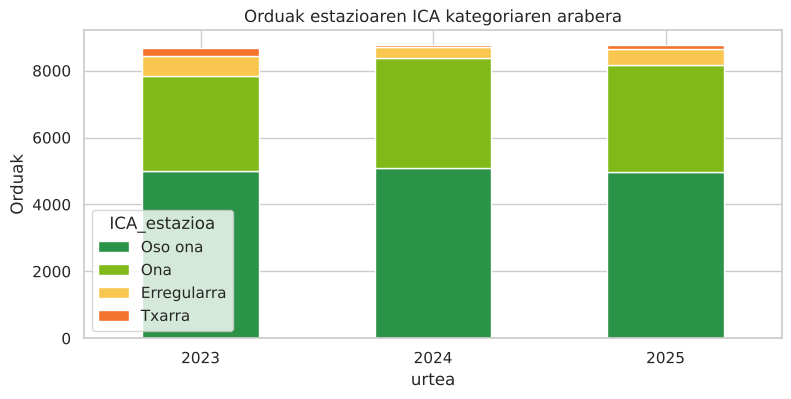

ICA_estazioa
Oso ona        57.48
Ona            35.54
Erregularra     5.46
Txarra          1.52
Name: proportion, dtype: float64

In [22]:
# Estazioaren ICA kategoria bakoitzeko ordu kopurua, urteka
ica_urtea = pd.crosstab(df["urtea"], df["ICA_estazioa"])
ica_urtea = ica_urtea[[k for k in ICA_ORDENA if k in ica_urtea.columns]]
ica_urtea.plot(kind="bar", stacked=True, figsize=(9, 4), rot=0,
               color=["#2b9348", "#80b918", "#f9c74f", "#f3722c"])
plt.title("Orduak estazioaren ICA kategoriaren arabera")
plt.ylabel("Orduak")
plt.show()

# Ehuneko osoa
(df["ICA_estazioa"].value_counts(normalize=True) * 100).round(2)

In [23]:
# Zein kutsatzailek eragiten ditu ordu Erregularrak edo Txarrak?
ordu_txarrak = df[df["ICA_estazioa"].isin(["Erregularra", "Txarra"])]
laburpena = {}
for zutabea in ["ICA_NO2", "ICA_PM10", "ICA_PM25", "ICA_SO2"]:
    laburpena[zutabea] = ordu_txarrak[zutabea].value_counts()
pd.DataFrame(laburpena).fillna(0).astype(int)

,ICA_NO2,ICA_PM10,ICA_PM25,ICA_SO2
Erregularra,0,1349,466,0
Ona,232,3,958,0
Oso ona,1586,0,40,1790
Txarra,0,337,132,0


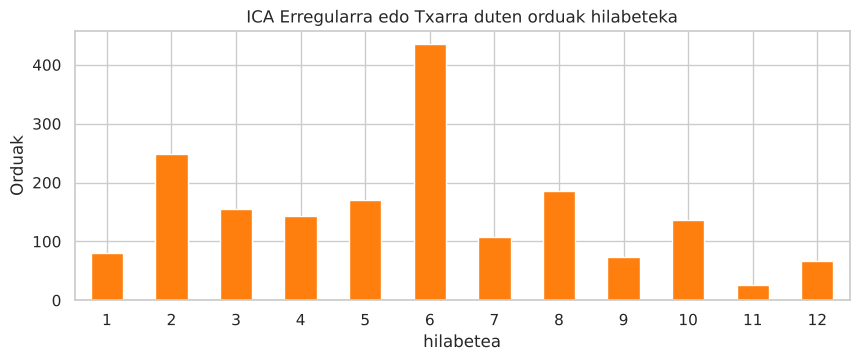

In [24]:
# Zein hilabetetan dago ordu Erregular edo Txar gehien
ordu_txarrak.groupby("hilabetea").size().plot(kind="bar", figsize=(10, 3.5), rot=0, color="tab:orange")
plt.title("ICA Erregularra edo Txarra duten orduak hilabeteka")
plt.ylabel("Orduak")
plt.show()

#### Ondorioak

- Airea ona da denbora gehienean: % 57 "Oso ona" eta % 35 "Ona". "Erregularra" % 5,4 da eta "Txarra" % 1,5.
- Klaseak oso desorekatuta daudenez, sailkapenean F1 bezalako metrikak begiratu beharko ditugu, ez accuracy bakarrik.
- Ordu txarrak beti partikulek eragiten dituzte, ez NO2ak.
- 2023ko udan PM10 falta denez, orduan ICA baikorregia izan daiteke.

## 9. Muturreko balioak (outlierrak)

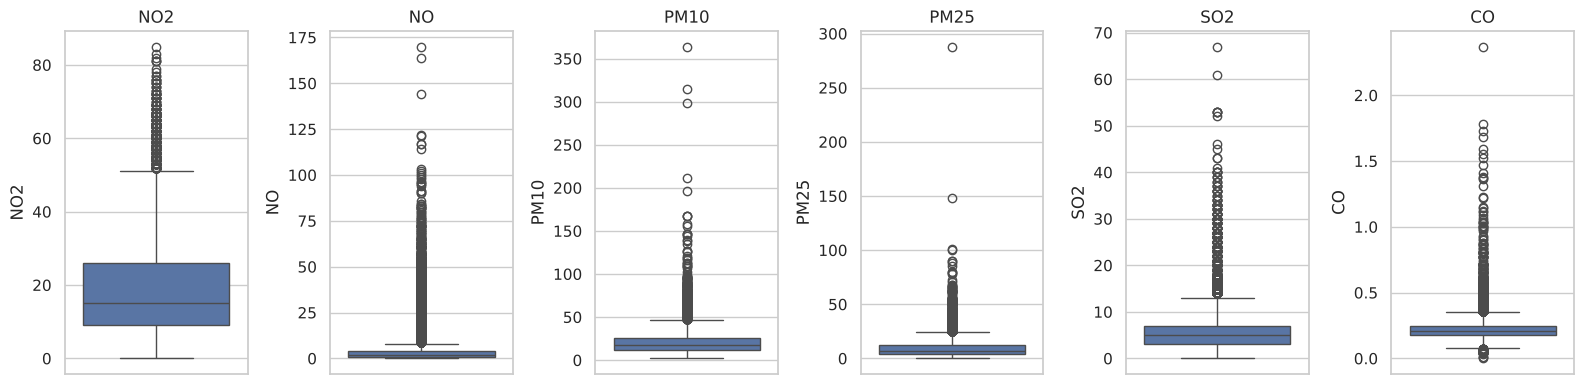

In [25]:
# Kutsatzaileen kutxa-diagramak
fig, ardatzak = plt.subplots(1, 6, figsize=(16, 4))
for ardatza, aldagaia in zip(ardatzak, ["NO2", "NO", "PM10", "PM25", "SO2", "CO"]):
    sns.boxplot(y=df[aldagaia], ax=ardatza)
    ardatza.set_title(aldagaia)
plt.tight_layout()
plt.show()

In [26]:
# PM10 gehien duten 10 orduak
df.nlargest(10, "PM10")[["PM10", "PM25", "NO2", "haize_abiadura", "ICA_estazioa"]]

,PM10,PM25,NO2,haize_abiadura,ICA_estazioa
data,,,,,
2023-02-24 19:00:00,364.0,5.0,15.0,1.71,Ona
2023-01-01 02:00:00,315.0,288.0,9.0,0.72,Txarra
2023-01-16 11:00:00,299.0,42.0,16.0,1.87,Oso ona
2023-06-06 16:00:00,212.0,13.0,12.0,2.76,Txarra
2023-02-24 17:00:00,196.0,14.0,12.0,1.27,Ona
2023-04-27 19:00:00,167.0,101.0,47.0,1.09,Erregularra
2024-12-18 21:00:00,167.0,47.0,5.0,3.06,Erregularra
2025-12-01 04:00:00,167.0,NaN,24.0,1.98,Ona
2024-12-18 22:00:00,158.0,53.0,4.0,3.45,Txarra


In [27]:
# 2023ko Urteberri gauaren xehetasuna
df.loc["2022-12-31 22:00":"2023-01-01 08:00", ["PM10", "PM25", "NO2", "haize_abiadura"]]

,PM10,PM25,NO2,haize_abiadura
data,,,,
2023-01-01 01:00:00,113.0,90.0,15.0,0.48
2023-01-01 02:00:00,315.0,288.0,9.0,0.72
2023-01-01 03:00:00,47.0,46.0,3.0,1.17
2023-01-01 04:00:00,33.0,34.0,2.0,0.67
2023-01-01 05:00:00,32.0,33.0,5.0,1.00
2023-01-01 06:00:00,34.0,35.0,4.0,0.69
2023-01-01 07:00:00,31.0,32.0,3.0,1.25
2023-01-01 08:00:00,25.0,25.0,3.0,1.39


#### Ondorioak

Kutxa-diagramek outlier asko markatzen dituzte, baina gehienak episodio errealak dira. Adibidez, 2023ko Urteberri gauean PM10 315era eta PM2.5 288ra iritsi ziren, su artifizialengatik. Beraz, outlierrak mantendu egingo ditugu: sistemak hain zuzen ere horiek detektatu behar ditu.

## 10. Estazioen arteko desberdintasunak (2025)

Barakaldo inguruko hiru estaziorekin alderatzen dugu: Erandio, Sangroniz eta Bilbo-Mazarredo. Testuingurua ulertzeko bakarrik da; ereduek Barakaldo bakarrik erabiltzen dute.

In [28]:
estazioak = {"Barakaldo": estazioa_kargatu("../data/jatorrizkoak/BARAKALDO_2025.csv", "../data/jatorrizkoak/BARAKALDO_INDIZEA_2025.csv")}
for kodea, izena in [("ERANDIO", "Erandio"), ("SANGRONIZ", "Sangroniz"), ("MAZARREDO", "Bilbo (Mazarredo)")]:
    estazioak[izena] = estazioa_kargatu("../data/jatorrizkoak/beste_estazioak/" + kodea + "_2025.csv",
                                        "../data/jatorrizkoak/beste_estazioak/" + kodea + "_INDIZEA_2025.csv")

# 2025eko batez bestekoak eta ICA kategorien banaketa estazio bakoitzean
errenkadak = []
for izena, datuak in estazioak.items():
    ica = datuak["ICA_estazioa"].value_counts(normalize=True) * 100
    errenkadak.append([izena, datuak["NO2"].mean(), datuak["PM10"].mean(), datuak["PM25"].mean(),
                       ica.get("Erregularra", 0) + ica.get("Txarra", 0)])
estazioen_laburpena = pd.DataFrame(errenkadak, columns=["estazioa", "NO2 batez bestekoa", "PM10 batez bestekoa", "PM2.5 batez bestekoa", "% ordu Erregular edo Txar"])
estazioen_laburpena.round(1)

,estazioa,NO2 batez bestekoa,PM10 batez bestekoa,PM2.5 batez bestekoa,% ordu Erregular edo Txar
0,Barakaldo,18.8,20.6,8.6,6.6
1,Erandio,18.2,15.5,8.7,4.0
2,Sangroniz,13.4,14.1,8.8,2.1
3,Bilbo (Mazarredo),19.9,14.2,8.6,2.3


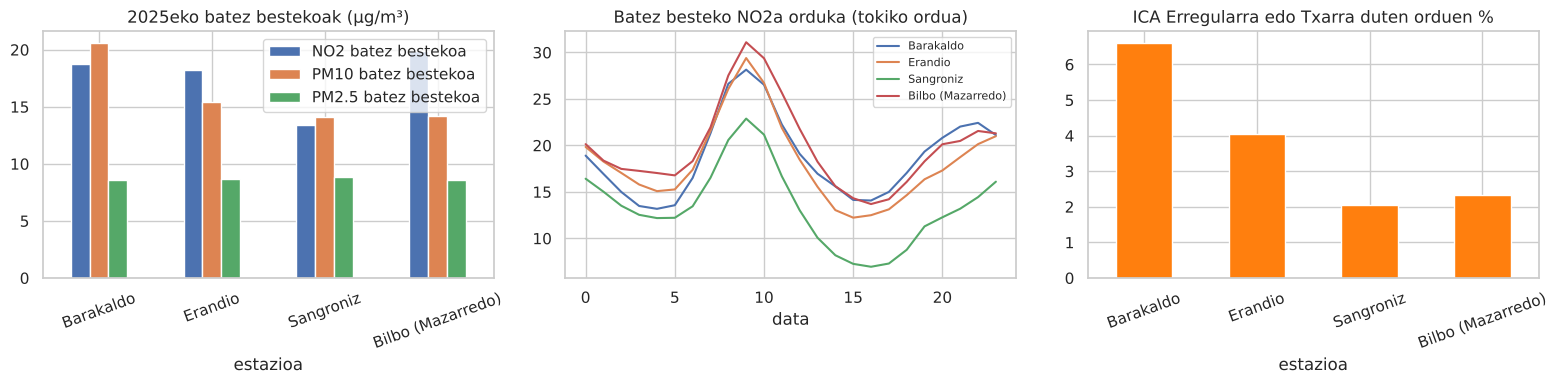

In [29]:
fig, ardatzak = plt.subplots(1, 3, figsize=(16, 4))
estazioen_laburpena.set_index("estazioa")[["NO2 batez bestekoa", "PM10 batez bestekoa", "PM2.5 batez bestekoa"]].plot(kind="bar", ax=ardatzak[0], rot=20)
ardatzak[0].set_title("2025eko batez bestekoak (µg/m³)")

for izena, datuak in estazioak.items():
    tokiko_ordua = datuak.index.tz_localize("UTC").tz_convert("Europe/Madrid").hour
    datuak["NO2"].groupby(tokiko_ordua).mean().plot(ax=ardatzak[1], label=izena)
ardatzak[1].set_title("Batez besteko NO2a orduka (tokiko ordua)")
ardatzak[1].legend(fontsize=8)

estazioen_laburpena.set_index("estazioa")["% ordu Erregular edo Txar"].plot(kind="bar", ax=ardatzak[2], rot=20, color="tab:orange")
ardatzak[2].set_title("ICA Erregularra edo Txarra duten orduen %")
plt.tight_layout()
plt.show()

#### Ondorioak

NO2 mailak eta orduko profila antzekoak dira estazio urbano guztietan, baina Barakaldok partikula gehiago ditu (PM10 ≈ 21, besteetan 14-16) eta ordu Erregular edo Txar gehiago. Partikulen tokiko iturriak daudela adierazten du; horregatik da estazio interesgarria alerta-sistema baterako.

## 11. EDAren ondorioak

- Datuak osoak dira; arazo nagusia 2023ko PM10 hutsunea da.
- NO2a trafikoaren mende dago eta eredu argiak ditu: erregresiorako hautagai ona.
- Haizeak asko eragiten du: baretarekin kutsadura metatu egiten da.
- Partikulek okertzen dute airearen kalitatea, beraz ICAren sailkapenak eta sistema adituak PM10 eta PM2.5 hartu behar dituzte kontuan.
- ICA klaseak oso desorekatuta daude.
- NOX eta CO_8h erredundanteak dira.
- Aldagai berri erabilgarriak: ordua, asteko eguna, hilabetea, haizearen sektorea eta aurreko orduetako NO2a.
- Outlierrak mantenduko ditugu.

## 12. 2026ko datuei begirada bat

Proba-datuak haien kalitatea ezagutzeko bakarrik begiratzen ditugu, ez erabakiak hartzeko.

In [30]:
df_2026 = datuak_kargatu("../data/jatorrizkoak", [2026])
print("2026:", df_2026.shape, "| noiztik", df_2026.index.min(), "noiz arte", df_2026.index.max())

# Nuluak eta ICA kategoriak, 2026 entrenamenduko urteekin alderatuta
display(pd.DataFrame({
    "% nuluak 2023-2025": (df[neurketa_zutabeak].isna().mean() * 100).round(1),
    "% nuluak 2026": (df_2026[neurketa_zutabeak].isna().mean() * 100).round(1),
}))
pd.DataFrame({
    "ICA 2023-2025 (%)": (df["ICA_estazioa"].value_counts(normalize=True) * 100).round(1),
    "ICA 2026 (%)": (df_2026["ICA_estazioa"].value_counts(normalize=True) * 100).round(1),
}).loc[ICA_ORDENA[:4]]

Urtea 2026 -> 7584 errenkada
2026: (7570, 18) | noiztik 2026-01-01 01:00:00 noiz arte 2026-11-12 10:00:00


,% nuluak 2023-2025,% nuluak 2026
CO,1.1,1.6
NO,1.0,1.6
NO2,1.0,4.2
PM10,19.1,4.6
PM25,3.2,1.9
SO2,2.5,5.6
tenperatura,6.0,30.7
hezetasuna,5.9,30.7
haize_abiadura,5.9,30.7
haize_norabidea,5.9,30.7


,ICA 2023-2025 (%),ICA 2026 (%)
ICA_estazioa,,
Oso ona,57.5,49.7
Ona,35.5,39.5
Erregularra,5.5,9.0
Txarra,1.5,1.8


#### Ondorioak

Ez da ordurik falta, baina meteorologia orduen % 31n falta da, 2023-2025ean baino askoz gehiago. Ereduek medianarekin bete beharko dituzte. Gainera, 2026an airea apur bat okerragoa izan da (ordu Erregular eta Txar gehiago), beraz proba zorrotza izango da.